# Adverderial attacks for class imbalance lending default datasets

In credit default predictions, financial institution work with highly class imbalanced datsets which require resampling in order to improve prediction of the positive class (default). The nature of the business case make the model susceptible to adverserial attacks because lenders with a high risk (predicted to default) will want to modify the features they have control in order to flip the prediction to either receive the lending or lower interest rate on the lending. A defence is to train the model with adversarial hardened examples but this is at the cost of accuracy, with this notebook we want to see if certain resampling models can adversarially 'harden' or 'weaken'models.

Authors:
- Tim Angevare
- Rick Hezeman 
- Ruben Stevenaar
- Roy Mulder

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

RANDOM_STATE = 42 #for reproducibility


%matplotlib inline

Loading the accepted lending dataset.

"This dataset contains the full LendingClub data available from their site. There are separate files for accepted and rejected loans. The accepted loans also include the FICO scores, which can only be downloaded when you are signed in to LendingClub and download the data." https://www.kaggle.com/datasets/wordsforthewise/lending-club

In [3]:
df = pd.read_csv("data/accepted.csv", low_memory=False)

## Section 1 exploring the dataset

In [4]:
print(f"Number of Records: {df.shape[0]:,.0f}")
print(f"Number of Features: {df.shape[1]}")

Number of Records: 2,260,701
Number of Features: 151


In [5]:
df.loan_status.value_counts()

loan_status
Fully Paid                                             1076751
Current                                                 878317
Charged Off                                             268559
Late (31-120 days)                                       21467
In Grace Period                                           8436
Late (16-30 days)                                         4349
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     40
Name: count, dtype: int64

For this research we only care about paid off and defaulted a.k.a charged off

In [6]:
df = df[df.loan_status.isin(['Fully Paid', 'Charged Off'])]

In [7]:
print("Columns:")
for col in df.columns:
    print(f" - {col}")

Columns:
 - id
 - member_id
 - loan_amnt
 - funded_amnt
 - funded_amnt_inv
 - term
 - int_rate
 - installment
 - grade
 - sub_grade
 - emp_title
 - emp_length
 - home_ownership
 - annual_inc
 - verification_status
 - issue_d
 - loan_status
 - pymnt_plan
 - url
 - desc
 - purpose
 - title
 - zip_code
 - addr_state
 - dti
 - delinq_2yrs
 - earliest_cr_line
 - fico_range_low
 - fico_range_high
 - inq_last_6mths
 - mths_since_last_delinq
 - mths_since_last_record
 - open_acc
 - pub_rec
 - revol_bal
 - revol_util
 - total_acc
 - initial_list_status
 - out_prncp
 - out_prncp_inv
 - total_pymnt
 - total_pymnt_inv
 - total_rec_prncp
 - total_rec_int
 - total_rec_late_fee
 - recoveries
 - collection_recovery_fee
 - last_pymnt_d
 - last_pymnt_amnt
 - next_pymnt_d
 - last_credit_pull_d
 - last_fico_range_high
 - last_fico_range_low
 - collections_12_mths_ex_med
 - mths_since_last_major_derog
 - policy_code
 - application_type
 - annual_inc_joint
 - dti_joint
 - verification_status_joint
 - acc_no

In [8]:
df.head()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,68407277,NaN,3600.0,3600.0,3600.0,36 months,13.99,123.03,C,C4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,68355089,NaN,24700.0,24700.0,24700.0,36 months,11.99,820.28,C,C1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,68341763,NaN,20000.0,20000.0,20000.0,60 months,10.78,432.66,B,B4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
4,68476807,NaN,10400.0,10400.0,10400.0,60 months,22.45,289.91,F,F1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
5,68426831,NaN,11950.0,11950.0,11950.0,36 months,13.44,405.18,C,C3,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
missing = df.isnull().sum()
missing

id                             0
member_id                1345310
loan_amnt                      0
funded_amnt                    0
funded_amnt_inv                0
                          ...   
settlement_status        1312034
settlement_date          1312034
settlement_amount        1312034
settlement_percentage    1312034
settlement_term          1312034
Length: 151, dtype: int64

We see a lot of nan values so lets drop the features that have a lot of NaN values

In [10]:
missing_percent = (missing / len(df)) * 100

missing_table = pd.DataFrame({
    'Missing Values': missing,
    'Percentage (%)': missing_percent
})

missing_table = missing_table.sort_values(by='Percentage (%)', ascending=False)
pd.set_option('display.max_rows', None)

missing_table

,Missing Values,Percentage (%)
member_id,1345310,100.000000
next_pymnt_d,1345310,100.000000
orig_projected_additional_accrued_interest,1341551,99.720585
hardship_payoff_balance_amount,1339556,99.572292
hardship_last_payment_amount,1339556,99.572292
hardship_reason,1339556,99.572292
hardship_type,1339556,99.572292
hardship_status,1339556,99.572292
hardship_amount,1339556,99.572292
deferral_term,1339556,99.572292


In [11]:
cols_to_drop = missing_table[missing_table['Percentage (%)'] > 50].index # Selects columsn with > 50% missing and returns their names

print("Columns to drop:")
for col in cols_to_drop:
    print(f" - {col}")

df = df.drop(columns=cols_to_drop, errors='ignore')

Columns to drop:
 - member_id
 - next_pymnt_d
 - orig_projected_additional_accrued_interest
 - hardship_payoff_balance_amount
 - hardship_last_payment_amount
 - hardship_reason
 - hardship_type
 - hardship_status
 - hardship_amount
 - deferral_term
 - hardship_end_date
 - hardship_dpd
 - hardship_loan_status
 - hardship_length
 - payment_plan_start_date
 - hardship_start_date
 - sec_app_mths_since_last_major_derog
 - sec_app_revol_util
 - revol_bal_joint
 - sec_app_inq_last_6mths
 - sec_app_mort_acc
 - sec_app_chargeoff_within_12_mths
 - sec_app_earliest_cr_line
 - sec_app_open_act_il
 - sec_app_fico_range_high
 - sec_app_fico_range_low
 - sec_app_num_rev_accts
 - sec_app_collections_12_mths_ex_med
 - sec_app_open_acc
 - verification_status_joint
 - dti_joint
 - annual_inc_joint
 - debt_settlement_flag_date
 - settlement_percentage
 - settlement_date
 - settlement_term
 - settlement_status
 - settlement_amount
 - desc
 - mths_since_last_record
 - mths_since_recent_bc_dlq
 - mths_since_

In [12]:
df.shape

(1345310, 93)

Following the Kaggle notebooks we will keep the following collumns

Update: We removed Int_rate and grade as these are proxy features for defaults. from the Wikipedia page from lending club: 'To reduce default risk, LendingClub focuses on high-credit-worthy borrowers, declining approximately 90% of the loan applications it received as of 2012[77] and assigning higher interest rates to riskier borrowers within its credit criteria.[26] Only borrowers with FICO score of 660 or higher can be approved for loans.[67]' - https://en.wikipedia.org/wiki/LendingClub#Credit_risk

| # | Feature | Description |
|---|---------|-------------|
| 0 | `loan_amnt` | The listed amount of the loan applied for by the borrower. If at some point in time, the credit department reduces the loan amount, then it will be reflected in this value. |
| 1 | `term` | The number of payments on the loan. Values are in months and can be either 36 or 60. |
| 3 | `installment` | The monthly payment owed by the borrower if the loan originates. |
| 6 | `emp_length` | Employment length in years. Possible values are between 0 and 10 where 0 means less than one year and 10 means ten or more years. |
| 7 | `home_ownership` | The home ownership status provided by the borrower during registration or obtained from the credit report. Values: RENT, OWN, MORTGAGE, OTHER |
| 8 | `annual_inc` | The self-reported annual income provided by the borrower during registration. |
| 9 | `verification_status` | Indicates if income was verified by LC, not verified, or if the income source was verified |
| 10 | `issue_d` | The month which the loan was funded |
| 11 | `loan_status` | Current status of the loan |
| 12 | `purpose` | A category provided by the borrower for the loan request. |
| 13 | `title` | The loan title provided by the borrower |
| 15 | `addr_state` | The state provided by the borrower in the loan application |
| 16 | `dti` | A ratio calculated using the borrower's total monthly debt payments on the total debt obligations, excluding mortgage and the requested LC loan, divided by the borrower's self-reported monthly income. |
| 17 | `earliest_cr_line` | The month the borrower's earliest reported credit line was opened |
| 18 | `open_acc` | The number of open credit lines in the borrower's credit file. |
| 19 | `pub_rec` | Number of derogatory public records |
| 20 | `revol_bal` | Total credit revolving balance |
| 21 | `revol_util` | Revolving line utilization rate, or the amount of credit the borrower is using relative to all available revolving credit. |
| 22 | `total_acc` | The total number of credit lines currently in the borrower's credit file |
| 23 | `initial_list_status` | The initial listing status of the loan. Possible values are W, F |
| 24 | `application_type` | Indicates whether the loan is an individual application or a joint application with two co-borrowers |
| 25 | `mort_acc` | Number of mortgage accounts. |
| 26 | `pub_rec_bankruptcies` | Number of public record bankruptcies. |

In [13]:
df.columns

Index(['id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate',
       'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length',
       'home_ownership', 'annual_inc', 'verification_status', 'issue_d',
       'loan_status', 'pymnt_plan', 'url', 'purpose', 'title', 'zip_code',
       'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line',
       'fico_range_low', 'fico_range_high', 'inq_last_6mths', 'open_acc',
       'pub_rec', 'revol_bal', 'revol_util', 'total_acc',
       'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt',
       'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int',
       'total_rec_late_fee', 'recoveries', 'collection_recovery_fee',
       'last_pymnt_d', 'last_pymnt_amnt', 'last_credit_pull_d',
       'last_fico_range_high', 'last_fico_range_low',
       'collections_12_mths_ex_med', 'policy_code', 'application_type',
       'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'total_rev_hi_lim',
       'acc_open_past_24mths', 'a

In [14]:
df['purpose'].value_counts()

purpose
debt_consolidation    780321
credit_card           295279
home_improvement       87504
other                  77875
major_purchase         29425
medical                15554
small_business         15416
car                    14585
moving                  9480
vacation                9065
house                   7253
wedding                 2294
renewable_energy         933
educational              326
Name: count, dtype: int64

In [15]:
df = df[[
    'loan_amnt', 'term', 'installment', 'emp_length',
    'home_ownership', 'annual_inc', 'verification_status', 'issue_d',
    'loan_status', 'purpose', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line',
    'fico_range_low', 'fico_range_high', 'inq_last_6mths', 'open_acc',
    'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status',
    'application_type', 'mort_acc', 'pub_rec_bankruptcies'
]]

In [16]:
df.describe()

,loan_amnt,installment,annual_inc,dti,delinq_2yrs,fico_range_low,fico_range_high,inq_last_6mths,open_acc,pub_rec,revol_bal,revol_util,total_acc,mort_acc,pub_rec_bankruptcies
count,1.345310e+06,1.345310e+06,1.345310e+06,1.344936e+06,1.345310e+06,1.345310e+06,1.345310e+06,1.345309e+06,1.345310e+06,1.345310e+06,1.345310e+06,1.344453e+06,1.345310e+06,1.298029e+06,1.344613e+06
mean,1.441997e+04,4.380755e+02,7.624764e+04,1.828267e+01,3.177944e-01,6.961850e+02,7.001852e+02,6.550807e-01,1.159352e+01,2.152760e-01,1.624811e+04,5.181002e+01,2.498084e+01,1.670783e+00,1.344439e-01
std,8.717051e+03,2.615126e+02,6.992510e+04,1.116045e+01,8.779922e-01,3.185251e+01,3.185316e+01,9.377739e-01,5.473789e+00,6.018647e-01,2.232817e+04,2.452107e+01,1.199847e+01,2.000444e+00,3.779285e-01
min,5.000000e+02,4.930000e+00,0.000000e+00,-1.000000e+00,0.000000e+00,6.250000e+02,6.290000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.000000e+00,0.000000e+00,0.000000e+00
25%,8.000000e+03,2.484800e+02,4.578000e+04,1.179000e+01,0.000000e+00,6.700000e+02,6.740000e+02,0.000000e+00,8.000000e+00,0.000000e+00,5.943000e+03,3.340000e+01,1.600000e+01,0.000000e+00,0.000000e+00
50%,1.200000e+04,3.754300e+02,6.500000e+04,1.761000e+01,0.000000e+00,6.900000e+02,6.940000e+02,0.000000e+00,1.100000e+01,0.000000e+00,1.113400e+04,5.220000e+01,2.300000e+01,1.000000e+00,0.000000e+00
75%,2.000000e+04,5.807300e+02,9.000000e+04,2.406000e+01,0.000000e+00,7.100000e+02,7.140000e+02,1.000000e+00,1.400000e+01,0.000000e+00,1.975575e+04,7.070000e+01,3.200000e+01,3.000000e+00,0.000000e+00
max,4.000000e+04,1.719830e+03,1.099920e+07,9.990000e+02,3.900000e+01,8.450000e+02,8.500000e+02,8.000000e+00,9.000000e+01,8.600000e+01,2.904836e+06,8.923000e+02,1.760000e+02,5.100000e+01,1.200000e+01


In [17]:
df.dtypes

loan_amnt               float64
term                        str
installment             float64
emp_length                  str
home_ownership              str
annual_inc              float64
verification_status         str
issue_d                     str
loan_status                 str
purpose                     str
addr_state                  str
dti                     float64
delinq_2yrs             float64
earliest_cr_line            str
fico_range_low          float64
fico_range_high         float64
inq_last_6mths          float64
open_acc                float64
pub_rec                 float64
revol_bal               float64
revol_util              float64
total_acc               float64
initial_list_status         str
application_type            str
mort_acc                float64
pub_rec_bankruptcies    float64
dtype: object

We ant to predict the rate of default so we wil rename it to target

In [18]:
df = df.rename(columns={"loan_status": "target"})
df["target"] = df["target"].map({"Charged Off": 1, "Fully Paid": 0})


# Visualisation of the dataset

In [19]:
df.groupby("target").count()

,loan_amnt,term,installment,emp_length,home_ownership,annual_inc,verification_status,issue_d,purpose,addr_state,...,inq_last_6mths,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,application_type,mort_acc,pub_rec_bankruptcies
target,,,,,,,,,,,,,,,,,,,,,
0,1076751,1076751,1076751,1019370,1076751,1076751,1076751,1076751,1076751,1076751,...,1076750,1076751,1076751,1076751,1076074,1076751,1076751,1076751,1036356,1076172
1,268559,268559,268559,247429,268559,268559,268559,268559,268559,268559,...,268559,268559,268559,268559,268379,268559,268559,268559,261673,268441


Lets look at the Default rate by Loan Purpose

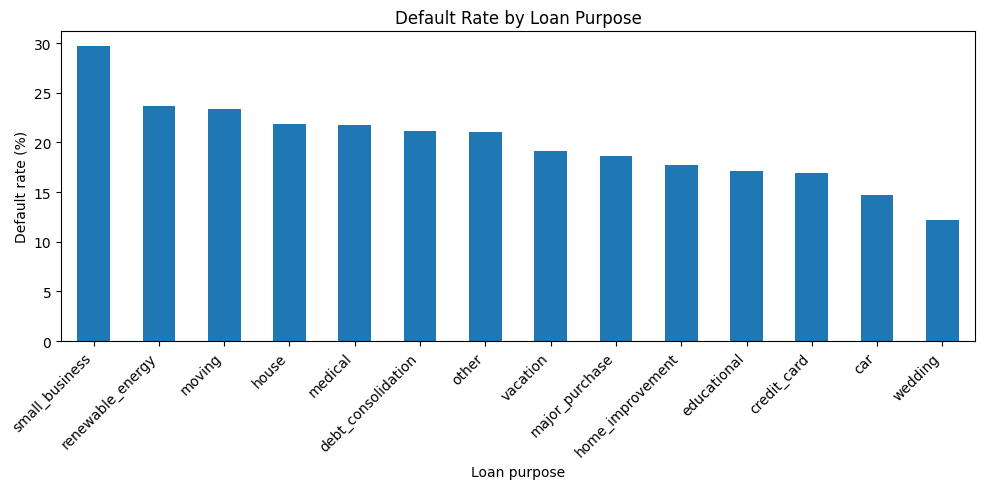

In [20]:
purpose_default_rate = (
    df.groupby("purpose")["target"].mean().sort_values(ascending=False) * 100
)

plt.figure(figsize=(10, 5))
purpose_default_rate.plot(kind="bar")

plt.title("Default Rate by Loan Purpose")
plt.xlabel("Loan purpose")
plt.ylabel("Default rate (%)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

What is the default rate per grade?

In [21]:
grade_default_rate = (
    df
    .groupby("grade")["target"]
    .mean()
    .sort_index() * 100
)

plt.figure(figsize=(6, 4))
grade_default_rate.plot(kind="bar")

plt.title("Default Rate by LendingClub Grade")
plt.xlabel("Grade")
plt.ylabel("Default rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

KeyError: 'grade'

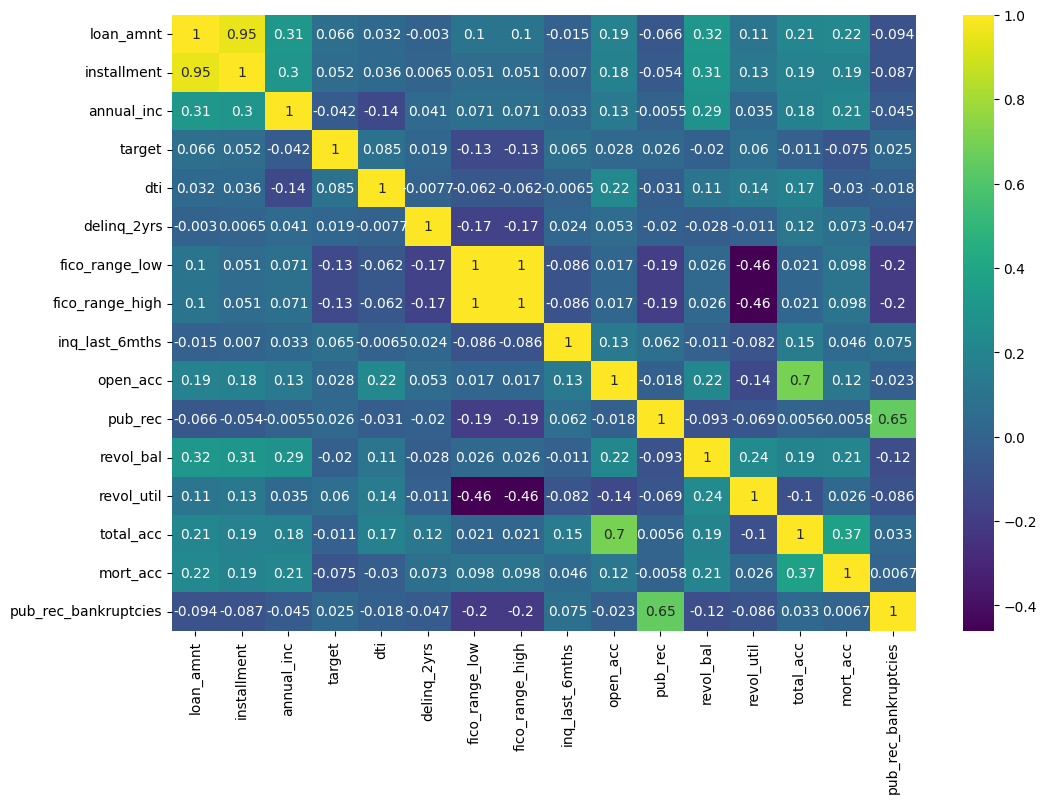

In [22]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='viridis')
plt.show()

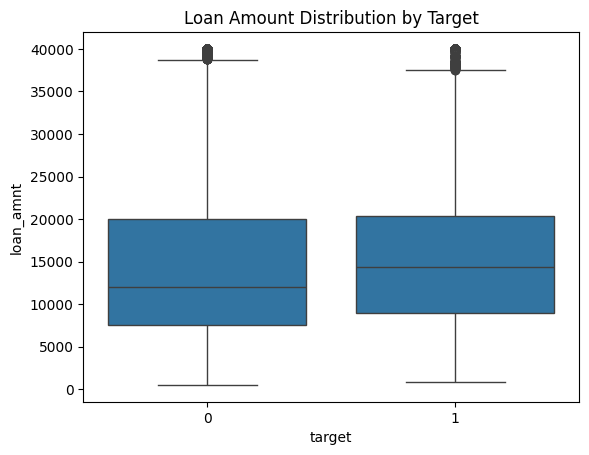

In [23]:
boxplot = sns.boxplot(x="target", y="loan_amnt", data=df)
boxplot.set_title("Loan Amount Distribution by Target")
plt.show()

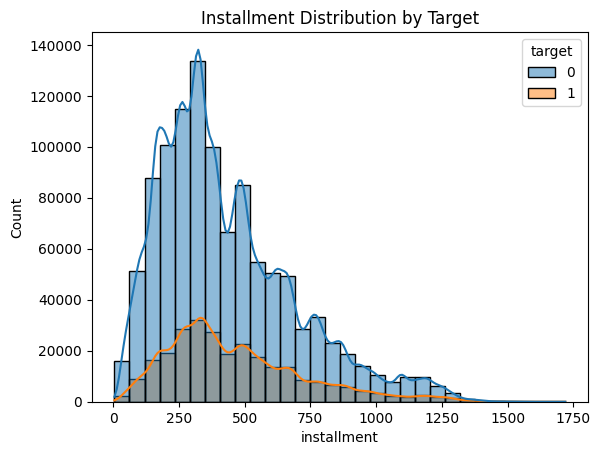

In [24]:
installment = sns.histplot(data=df, x="installment", hue="target", kde=True, bins=30)
installment.set_title("Installment Distribution by Target")

plt.show()


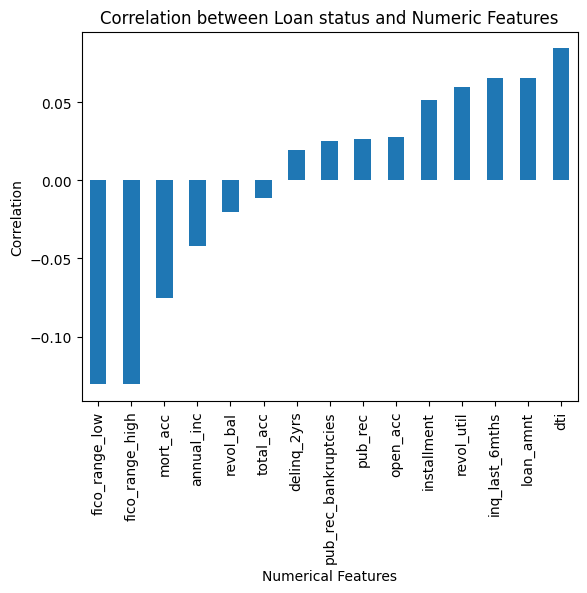

In [25]:
df.corr(numeric_only=True)['target'].drop('target').sort_values().plot(kind='bar',
    title="Correlation between Loan status and Numeric Features", 
    ylabel='Correlation', xlabel='Numerical Features', 
)
plt.show()

# Section 2 DPT

### Convert categorical features into numereric

In [26]:
df.dtypes

loan_amnt               float64
term                        str
installment             float64
emp_length                  str
home_ownership              str
annual_inc              float64
verification_status         str
issue_d                     str
target                    int64
purpose                     str
addr_state                  str
dti                     float64
delinq_2yrs             float64
earliest_cr_line            str
fico_range_low          float64
fico_range_high         float64
inq_last_6mths          float64
open_acc                float64
pub_rec                 float64
revol_bal               float64
revol_util              float64
total_acc               float64
initial_list_status         str
application_type            str
mort_acc                float64
pub_rec_bankruptcies    float64
dtype: object

In [27]:
df.application_type.unique()

<ArrowStringArray>
['Individual', 'Joint App']
Length: 2, dtype: str

Since `application_type` is just two values we binary encode

In [28]:
df['Individual application'] = df['application_type'] == 'INDIVIDUAL'
df.drop(columns=['application_type'], inplace=True)

In [29]:
df.emp_length.unique()

<ArrowStringArray>
['10+ years',   '3 years',   '4 years',   '6 years',   '7 years',   '8 years',
   '2 years',   '5 years',   '9 years',  '< 1 year',    '1 year',         nan]
Length: 12, dtype: str

The `emp_length` we can ordinally encode since there is an incemental relation

In [30]:
df["emp_length"] = df["emp_length"].map({"< 1 year": 0, "1 year": 1, "2 years": 2, "3 years": 3, "4 years": 4, "5 years": 5, "6 years": 6, "7 years": 7, "8 years": 8, "9 years": 9, "10+ years": 10})

In [31]:
df.term.value_counts()

term
36 months    1020743
60 months     324567
Name: count, dtype: int64

For the feature `term` we can strip the months and convert to integer

In [32]:
df["term"] = df["term"].fillna("36 months")

In [33]:
df["term"] = df["term"].str.strip().str.replace(" months", "").astype(int)

In [34]:
df.purpose.value_counts().head()

purpose
debt_consolidation    780321
credit_card           295279
home_improvement       87504
other                  77875
major_purchase         29425
Name: count, dtype: int64

In [35]:
df['verification_status'].value_counts()

verification_status
Source Verified    521273
Verified           418336
Not Verified       405701
Name: count, dtype: int64

In [36]:
df['initial_list_status'].value_counts()

initial_list_status
w    784010
f    561300
Name: count, dtype: int64

In [37]:
df['home_ownership'].value_counts()

home_ownership
MORTGAGE    665579
RENT        534421
OWN         144832
ANY            286
OTHER          144
NONE            48
Name: count, dtype: int64

In [38]:
df.dtypes == "object"

loan_amnt                 False
term                      False
installment               False
emp_length                False
home_ownership            False
annual_inc                False
verification_status       False
issue_d                   False
target                    False
purpose                   False
addr_state                False
dti                       False
delinq_2yrs               False
earliest_cr_line          False
fico_range_low            False
fico_range_high           False
inq_last_6mths            False
open_acc                  False
pub_rec                   False
revol_bal                 False
revol_util                False
total_acc                 False
initial_list_status       False
mort_acc                  False
pub_rec_bankruptcies      False
Individual application    False
dtype: bool

In [43]:
df['earliest_cr_line'].head()

0    Aug-2003
1    Dec-1999
2    Aug-2000
4    Jun-1998
5    Oct-1987
Name: earliest_cr_line, dtype: str

In [44]:
import locale
locale.setlocale(locale.LC_TIME, 'C')

'C'

In [45]:
df["earliest_cr_line"] = pd.to_datetime(df["earliest_cr_line"], format="%b-%Y")

# Credit history length in years, relative to a fixed reference (dataset ~2018)
reference = pd.Timestamp("2018-01-01")
df["credit_history_yrs"] = (reference - df["earliest_cr_line"]).dt.days / 365.25

df.drop(columns="earliest_cr_line", inplace=True)

### Feature engineering
`fico_range_low` and `fico_range_high` are nearly identical, so we combine them into a single `fico_mid` feature.

In [46]:
df["fico_mid"] = (df["fico_range_low"] + df["fico_range_high"]) / 2
df.drop(columns=["fico_range_low", "fico_range_high"], inplace=True)



`annual_inc` and `revol_bal` are heavily right-skewed, so we log-transform them.

In [47]:

df["annual_inc"] = np.log1p(df["annual_inc"])
df["revol_bal"] = np.log1p(df["revol_bal"])

We need to drop issue date since it is data leakage as the model would no know if the loan has been approved or not before making its prediction

In [48]:
df.drop('issue_d', axis=1, inplace=True)


## Fill missing values

In [49]:
df.isnull().sum()

loan_amnt                     0
term                          0
installment                   0
emp_length                78511
home_ownership                0
annual_inc                    0
verification_status           0
target                        0
purpose                       0
addr_state                    0
dti                         374
delinq_2yrs                   0
inq_last_6mths                1
open_acc                      0
pub_rec                       0
revol_bal                     0
revol_util                  857
total_acc                     0
initial_list_status           0
mort_acc                  47281
pub_rec_bankruptcies        697
Individual application        0
credit_history_yrs            0
fico_mid                      0
dtype: int64

We see that multiple features have rows with 33 null values. Are these the same rows?

In [50]:
df[df['loan_amnt'].isnull() == True].isnull().sum()

loan_amnt                 0
term                      0
installment               0
emp_length                0
home_ownership            0
annual_inc                0
verification_status       0
target                    0
purpose                   0
addr_state                0
dti                       0
delinq_2yrs               0
inq_last_6mths            0
open_acc                  0
pub_rec                   0
revol_bal                 0
revol_util                0
total_acc                 0
initial_list_status       0
mort_acc                  0
pub_rec_bankruptcies      0
Individual application    0
credit_history_yrs        0
fico_mid                  0
dtype: int64

Yess these rows contain a lot of null vallues lets drop them

In [51]:
df = df.dropna(subset=['loan_amnt'])

In [52]:
df.isnull().sum()

loan_amnt                     0
term                          0
installment                   0
emp_length                78511
home_ownership                0
annual_inc                    0
verification_status           0
target                        0
purpose                       0
addr_state                    0
dti                         374
delinq_2yrs                   0
inq_last_6mths                1
open_acc                      0
pub_rec                       0
revol_bal                     0
revol_util                  857
total_acc                     0
initial_list_status           0
mort_acc                  47281
pub_rec_bankruptcies        697
Individual application        0
credit_history_yrs            0
fico_mid                      0
dtype: int64

In [53]:
df = df.dropna(subset=["target"])

Finally we One-hot Encode the rest

In [54]:

	
	

dummies = df.select_dtypes(include=['object', 'str']).columns.tolist()
	
	

df = pd.get_dummies(df, columns=dummies, drop_first=True)


### This dataset does not have that much class imbalance (20%) compared to financial datasets. For our research we want class imbalance, so we will randomly undersample to get the minority class to 1%, 5%, 10% and 20%

Add a helper function to give us insights if undersampling introduced bias

In [55]:
from scipy.stats import ks_2samp

def calc_bias(df, undersampled_df):
    results = {}
    for col in df.select_dtypes(include='number').columns:
        stat, p = ks_2samp(df[col], undersampled_df[col])
        results[col] = (stat, p)
    return results

In [ ]:
datasets = {}

minority_frac = [0.01, 0.02, 0.05, 0.1, 0.2]

majority = df[df["target"] == 0]
minority = df[df["target"] == 1]

natural_frac = len(minority) / (len(minority) + len(majority))
print(f"Natural minority fraction: {natural_frac:.3f}")

for frac in minority_frac:
    if frac <= natural_frac:

        n_minority = int(round(frac / (1 - frac) * len(majority)))
        maj_part = majority
        min_part = minority.sample(n=n_minority, random_state=RANDOM_STATE)
    else:

        n_majority = int(round((1 - frac) / frac * len(minority)))
        maj_part = majority.sample(n=n_majority, random_state=RANDOM_STATE)
        min_part = minority

    dataset = (
        pd.concat([maj_part, min_part])
        .sample(frac=1, random_state=RANDOM_STATE)
        .reset_index(drop=True)
    )
    X = dataset.drop(columns="target")
    y = dataset["target"]
    datasets[frac] = (X, y)
    print(f"Minority fraction: {frac}")
    print(y.value_counts())
    print(y.value_counts(normalize=True))
    print(f"Bias statistics (Kolmogorov-Smirnov test):")
    print(calc_bias(df, dataset))

Natural minority fraction: 0.200
Minority fraction: 0.01
target
0    1076751
1      10876
Name: count, dtype: int64
target
0    0.99
1    0.01
Name: proportion, dtype: float64
Bias statistics (Kolmogorov-Smirnov test):
{'loan_amnt': (np.float64(0.015728039077805678), np.float64(1.1692376504046194e-129)), 'term': (np.float64(0.03562055417328169), np.float64(0.0)), 'installment': (np.float64(0.013581308432251415), np.float64(8.697048288395085e-97)), 'emp_length': (np.float64(nan), np.float64(nan)), 'annual_inc': (np.float64(0.013683277355135304), np.float64(3.068570114587227e-98)), 'target': (np.float64(0.18962635672744466), np.float64(0.0)), 'dti': (np.float64(nan), np.float64(nan)), 'delinq_2yrs': (np.float64(0.003383159739621), np.float64(2.0941518146029804e-06)), 'inq_last_6mths': (np.float64(nan), np.float64(nan)), 'open_acc': (np.float64(0.0055687780552112764), np.float64(1.2579609846216283e-16)), 'pub_rec': (np.float64(0.005625562504159798), np.float64(5.855830423285003e-17)), 're

# Section 3 resampling

For oversampling techinques we will use:
- Class weighting (cost-sensitive Learning)
- Random Under-Sampling
- SMOTE-ENN (Edited Nearest Neighbour)
- K-Means SMOTE

We compare this with the baseline (highly imbalanced) and using classweight


In [57]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTEENN
from imblearn.over_sampling import SMOTENC
from imblearn.over_sampling import KMeansSMOTE
from sklearn.model_selection import StratifiedKFold
from sklearn.cluster import MiniBatchKMeans
from sklearn.preprocessing import StandardScaler

For KMeansSMOTE we want to find out the optimal amount of clusters so we use the elbow method

In [58]:
from sklearn.cluster import KMeans
from sklearn import metrics
from scipy.spatial.distance import cdist
from sklearn.impute import SimpleImputer

In [59]:
distortions = []
inertias = []
mapping1 = {}
mapping2 = {}

X = datasets[0.1][0]  # Using the dataset with 10% minority fraction for clustering
imputer = SimpleImputer(strategy='mean')
X_imputed = imputer.fit_transform(X)

K = range(10, 100, 10)

for k in K:
    print(f"Calculating distortions and inertias for k={k}...")

    kmeansModel = KMeans(n_clusters=k, random_state=RANDOM_STATE).fit(X_imputed)  # Using the dataset with 10% minority fraction for clustering
    distortions.append(sum(np.min(cdist(X_imputed, kmeansModel.cluster_centers_, 'euclidean'), axis=1)**2) / X_imputed.shape[0])

    inertias.append(kmeansModel.inertia_)

    print(f"Distortion for k={k}: {distortions[-1]}")
    print(f"Inertia for k={k}: {inertias[-1]}")

    mapping1[k] = distortions[-1]
    mapping2[k] = inertias[-1]

Calculating distortions and inertias for k=10...


c:\Users\tim_a\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\tim_a\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\tim_a\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\tim_a\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\tim_a\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

Distortion for k=10: 858183.3385991938
Inertia for k=10: 1026721964466.6458
Calculating distortions and inertias for k=20...
Distortion for k=20: 190098.3150229616
Inertia for k=20: 227431723110.31964
Calculating distortions and inertias for k=30...
Distortion for k=30: 67076.8541643949
Inertia for k=30: 80250077553.73734
Calculating distortions and inertias for k=40...
Distortion for k=40: 40539.58549994179
Inertia for k=40: 48501154696.27716
Calculating distortions and inertias for k=50...
Distortion for k=50: 24830.786591878692
Inertia for k=50: 29707304770.655857
Calculating distortions and inertias for k=60...
Distortion for k=60: 17346.138288310758
Inertia for k=60: 20752746386.752586
Calculating distortions and inertias for k=70...
Distortion for k=70: 14340.27881620199
Inertia for k=70: 17156566172.91633
Calculating distortions and inertias for k=80...
Distortion for k=80: 11583.711111565099
Inertia for k=80: 13858636136.764364
Calculating distortions and inertias for k=90...
D

Distortion values:
10 : 858183.3385991938
20 : 190098.3150229616
30 : 67076.8541643949
40 : 40539.58549994179
50 : 24830.786591878692
60 : 17346.138288310758
70 : 14340.27881620199
80 : 11583.711111565099
90 : 10215.22971702599


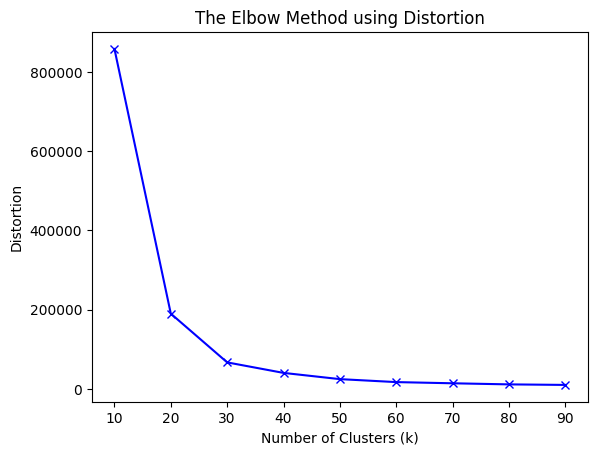

In [60]:
print("Distortion values:")
for key, val in mapping1.items():
    print(f'{key} : {val}')

plt.plot(K, distortions, 'bx-')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Distortion')
plt.title('The Elbow Method using Distortion')
plt.show()

Inertia values:
10 : 1026721964466.6458
20 : 227431723110.31964
30 : 80250077553.73734
40 : 48501154696.27716
50 : 29707304770.655857
60 : 20752746386.752586
70 : 17156566172.91633
80 : 13858636136.764364
90 : 12221398681.151876


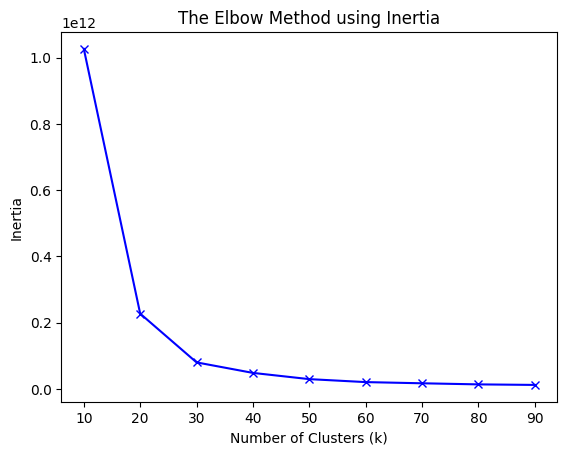

In [61]:
print("Inertia values:")
for key, val in mapping2.items():
    print(f'{key} : {val}')

plt.plot(K, inertias, 'bx-')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('The Elbow Method using Inertia')
plt.show()

In [ ]:
NUM_CLUSTERS = 30  # Chosen based on the elbow method results

Define our samplers

In [ ]:
samplers = {
    "Baseline": None,   
    "RandomUnderSampler": RandomUnderSampler(sampling_strategy="majority", random_state=RANDOM_STATE),
    "SMOTEENN":           SMOTEENN(sampling_strategy="minority", random_state=RANDOM_STATE),
    "KMeansSMOTE": KMeansSMOTE(
        sampling_strategy="minority",
        random_state=RANDOM_STATE,
        cluster_balance_threshold=0.01,
        kmeans_estimator=MiniBatchKMeans(n_clusters=NUM_CLUSTERS, random_state=RANDOM_STATE, n_init=3),
    ),
    "ClassWeight":        None,
}

Define our Kfold

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Section 4 Model Implementation

We will implement the following models that have surfaced in the literature review:
- Random forest
- Logistic regression (since this is the most explainable model with the best performance)
- XGBoost (Black box tree based model)
- Neural Network

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from torch import nn

from sklearn.model_selection import cross_validate
from time import process_time
from sklearn.impute import KNNImputer

import numpy as np
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    f1_score, precision_score, recall_score, precision_recall_curve,
)
from imblearn.metrics import geometric_mean_score
from sklearn.preprocessing import FunctionTransformer

First define some helper functions

In [ ]:
results = []

def best_f1_threshold(y_true, y_proba):
    precision, recall, thresholds = precision_recall_curve(y_true, y_proba)
    f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
    return thresholds[np.argmax(f1[:-1])]

#Helper for NN models that expect float32 input
def to_float32(X):
    return np.asarray(X, dtype=np.float32)

We want to define our pipeline to pass into the 5kfold. We add the imputer for NaN values and scale the values

In [ ]:
def build_pipeline(estimator, sampler):
    steps = [
        ("imputer", KNNImputer(n_neighbors=5, weights="distance")),
        ("scaler", StandardScaler()),
    ]
    if sampler is not None:
        steps.append(("sampler", sampler))
    if estimator.__class__.__name__ == "NeuralNetClassifier":
        steps.append(("to_float32", FunctionTransformer(to_float32)))
    steps.append(("clf", estimator))
    return ImbPipeline(steps)

We want to compute the SHAP scores for each training to see if resmapling methods alter feature importance

In [ ]:
import shap

shap_records = [] 

N_SHAP_MAX   = 200   # test samples for TreeExplainer / LinearExplainer
N_SHAP_NN    = 20    # test samples for NeuralNet (KernelExplainer is slow)
N_SHAP_NN_BG = 50    # background samples for KernelExplainer

In [ ]:
def preprocess_for_shap(pipe, X):
    # Remove resampler steps from the pipeline, as they are not used at inference time and may not support transform().
    X_t = X
    for _, step in pipe.steps[:-1]:
        if hasattr(step, "fit_resample"): 
            continue
        X_t = step.transform(X_t)
    return np.asarray(X_t)


def get_sv_class1(sv):
    # Normalise SHAP output to shape (n_samples, n_features) for the positive class.
    if isinstance(sv, list) and len(sv) == 2:
        return sv[1]
    if hasattr(sv, "values"):               # shap.Explanation object (SHAP >= 0.41)
        v = sv.values
        return v[:, :, 1] if v.ndim == 3 else v
    if isinstance(sv, np.ndarray) and sv.ndim == 3:
        return sv[:, :, 1]
    return sv


def compute_shap_for_fold(pipe, train_idx, test_idx, X, model_name, sampler_name, imbalance_ratio):
    rng = np.random.default_rng(RANDOM_STATE)
    clf  = pipe.named_steps["clf"]
    feat = list(X.columns)

    try:
        if model_name in ("XGBClassifier", "RandomForestClassifier"):
            X_te = preprocess_for_shap(pipe, X.iloc[test_idx])
            idx  = rng.choice(len(X_te), min(N_SHAP_MAX, len(X_te)), replace=False)
            sv   = get_sv_class1(shap.TreeExplainer(clf).shap_values(X_te[idx]))

        elif model_name == "LogisticRegression":
            X_tr = preprocess_for_shap(pipe, X.iloc[train_idx])
            X_te = preprocess_for_shap(pipe, X.iloc[test_idx])
            idx  = rng.choice(len(X_te), min(N_SHAP_MAX, len(X_te)), replace=False)
            sv   = get_sv_class1(shap.LinearExplainer(clf, X_tr).shap_values(X_te[idx]))

        elif model_name == "NeuralNetClassifier":
            X_te_raw = X.iloc[test_idx].astype(np.float32)
            X_tr_raw = X.iloc[train_idx].astype(np.float32)
            ei = rng.choice(len(X_te_raw), min(N_SHAP_NN,    len(X_te_raw)),  replace=False)
            bi = rng.choice(len(X_tr_raw), min(N_SHAP_NN_BG, len(X_tr_raw)), replace=False)

            def nn_predict(X_raw):
                df = pd.DataFrame(X_raw, columns=feat).astype(np.float32)
                return pipe.predict_proba(df)[:, 1]

            sv = shap.KernelExplainer(nn_predict, X_tr_raw.iloc[bi]).shap_values(
                X_te_raw.iloc[ei], nsamples=100, l1_reg="num_features(10)"
            )
        else:
            return

        shap_records.append({
            "Model":           model_name,
            "Sampler":         sampler_name,
            "Imbalance ratio": imbalance_ratio,
            "importances":     pd.Series(np.abs(sv).mean(axis=0), index=feat),
        })

    except Exception as e:
        print(f"  SHAP skipped for {model_name}+{sampler_name} (IR={imbalance_ratio}): {e}")

The scoring function

In [ ]:
def score_model(imbalance_ratio, cv_out, estimator, sampler_name, X, y, normalize='true'):
    y_arr = np.asarray(y)
    y_pred = np.empty_like(y_arr)
    fold_thresholds, train_f1s, test_f1s = [], [], []
    for est, train_idx, test_idx in zip(
        cv_out["estimator"], cv_out["indices"]["train"], cv_out["indices"]["test"]
    ):
        proba_train = est.predict_proba(X.iloc[train_idx])[:, 1]
        thr = best_f1_threshold(y_arr[train_idx], proba_train)
        proba_test = est.predict_proba(X.iloc[test_idx])[:, 1]
        y_pred[test_idx] = (proba_test >= thr).astype(y_arr.dtype)
        fold_thresholds.append(float(thr))
        train_f1s.append(f1_score(y_arr[train_idx], (proba_train >= thr).astype(y_arr.dtype), average="macro"))
        test_f1s.append(f1_score(y_arr[test_idx], y_pred[test_idx], average="macro"))

    cm = confusion_matrix(y_arr, y_pred, normalize=normalize)
    disp = ConfusionMatrixDisplay(cm, display_labels=np.unique(y_arr))
    disp.plot(cmap="Blues", values_format=".2f" if normalize else "d")
    plt.title(f"{estimator.__class__.__name__} + {sampler_name} + imbalance ratio {imbalance_ratio} ({skf.get_n_splits()}-fold OOF)")
    plt.show()

    train_f1 = float(np.mean(train_f1s))
    test_f1 = float(np.mean(test_f1s))

    results.append({
        "Model": estimator.__class__.__name__,
        "Sampler": sampler_name,
        "Imbalance ratio": imbalance_ratio,
        "fit time (s)": round(cv_out["fit_time"].mean(), 2),
        "Score time (s)": round(cv_out["score_time"].mean(), 2),
        "Threshold (mean)": round(float(np.mean(fold_thresholds)), 4),
        "F1 (mean)":        test_f1,
        "ROC-AUC (mean)":   cv_out["test_roc_auc"].mean(),
        "PR-AUC (mean)":    cv_out["test_average_precision"].mean(),
        "Recall (mean)":    recall_score(y_arr, y_pred, average="macro"),
        "Precision (mean)": precision_score(y_arr, y_pred, average="macro"),
        "G-Mean (mean)":    geometric_mean_score(y_arr, y_pred),
        "Train F1 (mean)":  train_f1,
        "F1 gap (train-test)": round(train_f1 - test_f1, 3),
        "TP": cm[1, 1] if normalize else int(cm[1, 1]),
        "FP": cm[0, 1] if normalize else int(cm[0, 1]),
        "TN": cm[0, 0] if normalize else int(cm[0, 0]),
        "FN": cm[1, 0] if normalize else int(cm[1, 0])
    })
    
    compute_shap_for_fold(
        cv_out["estimator"][-1],
        cv_out["indices"]["train"][-1],
        cv_out["indices"]["test"][-1],
        X,
        estimator.__class__.__name__,
        sampler_name,
        imbalance_ratio,
    )

Define our Kfold function

In [ ]:

def model_kfold(sampler_name, estimator, X, y, imbalance_ratio=None):
    print(f"Training {estimator.__class__.__name__} + {sampler_name} with imbalance ratio {imbalance_ratio}...")

    print("Performing cross-validation...")
    time_start = process_time()

    sampler = samplers[sampler_name]

    pipe = build_pipeline(estimator, sampler)

    cv_out = cross_validate(
        pipe, X, y, cv=skf,
        scoring=("roc_auc", "average_precision"),
        return_train_score=True,
        return_estimator=True,
        return_indices=True
    )

    print(f"Done in {round(process_time() - time_start, 2)} seconds.")

    score_model(imbalance_ratio, cv_out, estimator, sampler_name, X, y)

In [ ]:
import torch

Applying class weight is different per model so we have to define a function to compute this correctly

In [ ]:
def apply_class_weight(estimator, sampler_name, y):
    name = estimator.__class__.__name__
    y_arr = np.asarray(y)
    if sampler_name == "ClassWeight":
        if name in ("LogisticRegression", "RandomForestClassifier"):
            estimator.set_params(class_weight="balanced")
        elif name == "XGBClassifier":
            estimator.set_params(scale_pos_weight=(y_arr == 0).sum() / (y_arr == 1).sum())
        elif name == "NeuralNetClassifier":
            _, counts = np.unique(y_arr, return_counts=True)
            w = torch.tensor(counts.sum() / (2 * counts), dtype=torch.float32)
            estimator.set_params(criterion__weight=w)
    else:
        if name in ("LogisticRegression", "RandomForestClassifier"):
            estimator.set_params(class_weight=None)
        elif name == "XGBClassifier":
            estimator.set_params(scale_pos_weight=1.0)
        elif name == "NeuralNetClassifier":
            estimator.set_params(criterion__weight=None)
    return estimator

Now we implement our loops. First over all sampling methods, then over all imbalance ratios per model

In [ ]:
def loop_samplers(estimator, X, y, imbalance_ratio):
    for sampler_name, sampler in samplers.items(): 
        model_kfold(sampler_name, apply_class_weight(estimator, sampler_name, y), X, y, imbalance_ratio=imbalance_ratio)

In [ ]:
def loop_imbalance_ratios(estimator):
    for frac, dataset in datasets.items():
        print(f"=== Minority fraction: {frac} ===")
        X, y = dataset
        if estimator.__class__.__name__ == "NeuralNetClassifier":
            X = X.astype(np.float32)
            y = y.to_numpy().astype(np.int64)
            
        loop_samplers(estimator, X, y, imbalance_ratio=frac)

Before training on the various imbalance ratios we will first use gridsearch to find the optimal params for the models

In [ ]:
from sklearn.model_selection import GridSearchCV

config = {}

def find_best_hyperparameters(estimator, X, y, param_distributions):
    param_distributions["clf__random_state"] = [RANDOM_STATE]

    pipe = ImbPipeline([
        ("imputer", KNNImputer(neighbors=NUM_CLUSTERS, weights="distance")),
        ("scaler", StandardScaler()),
        ("clf", estimator)
    ])

    search = GridSearchCV(
        pipe,
        param_distributions,
        scoring="average_precision",
        refit=True,
        n_jobs=-1
    )

    search.fit(X, y)

    print("Best hyperparameters:")
    print(search.best_params_)

    print(f"Score with best hyperparameters: {search.best_score_:.4f}")

    config[estimator.__class__.__name__] = {k.removeprefix("clf__"): v for k, v in search.best_params_.items()}

In [ ]:
weight = (datasets[0.2][1] == 0).sum() / (datasets[0.2][1] == 1).sum()

In [ ]:

param_distributions_xgb = {
    "clf__n_estimators":     [400, 800],
    "clf__max_depth":        [4, 6],
    "clf__learning_rate":    [0.05, 0.1],
    "clf__min_child_weight": [1, 10],
    "clf__reg_lambda":       [1, 5],
    "clf__subsample":        [0.8],
    "clf__colsample_bytree": [0.8],
}


find_best_hyperparameters(XGBClassifier(), datasets[0.2][0], datasets[0.2][1], param_distributions_xgb)

In [ ]:
loop_imbalance_ratios(XGBClassifier(**config["XGBClassifier"]))

In [ ]:
param_distributions_logistic= {
    "clf__C": [0.01, 0.1, 1, 10],
    "clf__penalty": ["l1", "l2"],
    "clf__solver": ["saga"],
    "clf__max_iter": [2000],
}

find_best_hyperparameters(LogisticRegression(), datasets[0.2][0], datasets[0.2][1], param_distributions_logistic)

In [ ]:
loop_imbalance_ratios(LogisticRegression(**config["LogisticRegression"]))

In [ ]:
param_distributions_random_forest = {
    "clf__n_estimators":     [500],
    "clf__max_depth":        [None, 16, 24],
    "clf__min_samples_leaf": [1, 5, 20],     
    "clf__max_features":     ["sqrt", 0.3],
} 

find_best_hyperparameters(RandomForestClassifier(), datasets[0.2][0], datasets[0.2][1], param_distributions_random_forest)

In [ ]:
loop_imbalance_ratios(RandomForestClassifier(**config["RandomForestClassifier"]))

## Implement Neural Network

Define our neural network architecture

In [ ]:
class NeuralNetwork(nn.Module):

    def __init__(self, input_dim):

        super().__init__()

        self.layer_1 = nn.Linear(input_dim, 64)
        self.activation_1 = nn.ReLU()
        self.dropout_1 = nn.Dropout(0.2)
        self.layer_2 = nn.Linear(64, 64)
        self.activation_2 = nn.ReLU()
        self.dropout_2 = nn.Dropout(0.2)
        self.layer_3 = nn.Linear(64, 2)

    def forward(self, X):

        X = self.layer_1(X)
        X = self.activation_1(X)
        X = self.dropout_1(X)
        X = self.layer_2(X)
        X = self.activation_2(X)
        X = self.dropout_2(X)
        X = self.layer_3(X)

        return X


n_features = next(iter(datasets.values()))[0].shape[1]

Check if GPU is available

In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

In [ ]:
from skorch import NeuralNetClassifier
from skorch.callbacks import EarlyStopping, LRScheduler
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim import Adam

net_clf = NeuralNetClassifier(
    NeuralNetwork,
    module__input_dim=n_features,
    criterion=nn.CrossEntropyLoss,
    max_epochs=100,
    lr=0.001,
    device=device,
    optimizer=Adam,
    batch_size=512,
    iterator_train__shuffle=True,
    callbacks=[
    EarlyStopping(monitor='valid_loss', patience=10),
    LRScheduler(policy=ReduceLROnPlateau, monitor='valid_loss'),]
)

In [ ]:
loop_imbalance_ratios(net_clf)

## Evaluation of models & resampling methods

In [ ]:
model_results = pd.DataFrame(results)
model_results.to_csv("model_results.csv", index=False)
model_results

In [ ]:
ir_col   = "Imbalance ratio"
y_col    = "PR-AUC (mean)"

unique_samplers = model_results["Sampler"].unique()
models   = model_results["Model"].unique()

n = len(unique_samplers)
ncols = 3
nrows = -(-n // ncols) 

fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4.5 * nrows),
                         sharex=True, sharey=True)
axes = axes.flatten()

for ax, sampler in zip(axes, unique_samplers):
    sub = model_results[model_results["Sampler"] == sampler]
    for model in models:
        m = sub[sub["Model"] == model].sort_values(ir_col)
        if m.empty:
            continue
        ax.plot(m[ir_col], m[y_col], marker="o", label=model)

    ax.set_title(sampler)
    ax.set_xlabel("Imbalance Ratio")
    ax.set_ylabel(y_col)
    ax.grid(True, alpha=0.3)

for ax in axes[n:]:
    ax.set_visible(False)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center",
           ncol=len(models), bbox_to_anchor=(0.5, 1.02))

fig.tight_layout()
plt.show()


## Section 5b: Global SHAP Analysis

Mean absolute SHAP values are collected inside each CV run using the last fold's already-fitted pipeline so no models are retrained. Results cover all combinations of model × sampler × imbalance ratio.


In [ ]:
from matplotlib.patches import Patch

In [ ]:
# Features treated as directly mutable in the constrained attacks
mutable_features = [
    "loan_amnt",
    "annual_inc",
    "revol_bal",
]

TOP_N = 15

In [ ]:


shap_rows = []
for rec in shap_records:
    row = {"Model": rec["Model"], "Sampler": rec["Sampler"], "Imbalance ratio": rec["Imbalance ratio"]}
    row.update(rec["importances"].to_dict())
    shap_rows.append(row)

shap_wide = pd.DataFrame(shap_rows)
shap_wide.to_csv("shap_importances.csv", index=False)

feat_cols = [c for c in shap_wide.columns if c not in ("Model", "Sampler", "Imbalance ratio")]
shap_models_order = list(shap_wide["Model"].unique())

fig, axes = plt.subplots(1, len(shap_models_order), figsize=(6 * len(shap_models_order), 6))
axes = np.atleast_1d(axes)

for ax, model_name in zip(axes, shap_models_order):
    imp = shap_wide[shap_wide["Model"] == model_name][feat_cols].mean().nlargest(TOP_N)
    colors = ["tab:orange" if f in mutable_features else "tab:blue" for f in imp.index]
    imp[::-1].plot(kind="barh", ax=ax, color=colors[::-1])
    ax.set_title(model_name)
    ax.set_xlabel("Mean |SHAP value|")
fig.legend(
    handles=[
        Patch(facecolor="tab:orange", label="Adversarially mutable"),
        Patch(facecolor="tab:blue",   label="Not mutable"),
    ],
    loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.04),
)
fig.suptitle(
    f"Top {TOP_N} Global SHAP Features per Model  (averaged across samplers & imbalance ratios)",
    y=1.06,
)
plt.tight_layout()
plt.show()

for model_name in shap_models_order:
    sub  = shap_wide[shap_wide["Model"] == model_name]
    top5 = sub[feat_cols].mean().nlargest(5).index.tolist()

    fig, ax = plt.subplots(figsize=(8, 4))
    for feat in top5:
        grp = sub.groupby("Imbalance ratio")[feat].mean()
        ax.plot(grp.index, grp.values, marker="o", label=feat)
    ax.set_title(f"{model_name} — Top-5 SHAP features vs Imbalance Ratio")
    ax.set_xlabel("Imbalance Ratio")
    ax.set_ylabel("Mean |SHAP value|")
    ax.legend(loc="best", fontsize=8)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## Section 5c: Fairness / Disparate Impact Ratio (DIR)

This section evaluates whether the trained model gives the favourable prediction at different rates across groups.

- `emp_length`: shorter employment length as unprivileged, longer employment length as privileged.
- `annual_inc`: lower income as unprivileged, higher income as privileged.

Thresholds are fitted on the training split and then applied to the test split to avoid test-set leakage.

In [ ]:
# DIR configuration and helper functions
from sklearn.base import clone
from sklearn.metrics import accuracy_score

# target = 1 means default, so the favourable prediction is non-default.
FAVOURABLE_LABEL = 0

# For numerical features, use either:
# - method="threshold" with a fixed threshold, or
# - method="quantile" with a training-set quantile.
DIR_GROUP_SPECS = {
    "emp_length": {
        "method": "threshold",
        "threshold": 5,
        "unprivileged_if": "lower",   # lower than threshold = unprivileged
        "unprivileged_name": "emp_length < 5 years",
        "privileged_name": "emp_length >= 5 years",
    },
    "annual_inc": {
        "method": "quantile",
        "quantile": 0.50,             # median split based on the training set
        "unprivileged_if": "lower",
        "unprivileged_name": "lower annual income",
        "privileged_name": "higher annual income",
    },
}


def _get_group_threshold(feature, spec, X_reference):
    if spec["method"] == "threshold":
        return spec["threshold"]
    if spec["method"] == "quantile":
        return X_reference[feature].quantile(spec.get("quantile", 0.50))


def make_binary_groups(feature, values, spec, threshold):
    """Return privileged/unprivileged group labels for one feature."""
    if spec.get("unprivileged_if", "lower") == "lower":
        unprivileged_mask = values < threshold
    elif spec.get("unprivileged_if") == "higher":
        unprivileged_mask = values >= threshold

    return pd.Series(
        np.where(unprivileged_mask, spec["unprivileged_name"], spec["privileged_name"]),
        index=values.index,
        name=feature,
    )


def evaluate_dir_for_groups(
    y_true,
    y_pred,
    X_eval,
    X_reference,
    group_specs=DIR_GROUP_SPECS,
    favourable_label=FAVOURABLE_LABEL,
):
    y_true = pd.Series(np.asarray(y_true), index=X_eval.index, name="y_true")
    y_pred = pd.Series(np.asarray(y_pred), index=X_eval.index, name="y_pred")
    favourable_pred = (y_pred == favourable_label).astype(int)

    rows = []
    for feature, spec in group_specs.items():
        if feature not in X_eval.columns:
            print(f"Skipping {feature}: not found in X_eval")
            continue

        threshold = _get_group_threshold(feature, spec, X_reference)
        groups = make_binary_groups(feature, X_eval[feature], spec, threshold)

        tmp = pd.DataFrame({
            "group": groups,
            "y_true": y_true,
            "y_pred": y_pred,
            "favourable_pred": favourable_pred,
        })

        group_table = tmp.groupby("group").apply(
            lambda g: pd.Series({
                "n_samples": len(g),
                "favourable_prediction_rate": g["favourable_pred"].mean(),
                "default_prediction_rate": (g["y_pred"] == 1).mean(),
                "accuracy": accuracy_score(g["y_true"], g["y_pred"]),
            })
        )

        unpriv = spec["unprivileged_name"]
        priv = spec["privileged_name"]

        # Avoid divide-by-zero when the privileged group has no favourable predictions.
        priv_rate = group_table.loc[priv, "favourable_prediction_rate"] if priv in group_table.index else np.nan
        unpriv_rate = group_table.loc[unpriv, "favourable_prediction_rate"] if unpriv in group_table.index else np.nan
        dir_score = unpriv_rate / priv_rate if pd.notna(priv_rate) and priv_rate > 0 else np.nan

        for group_name, vals in group_table.iterrows():
            rows.append({
                "Feature": feature,
                "Group": group_name,
                "Role": "unprivileged" if group_name == unpriv else "privileged",
                "Threshold used": threshold,
                "DIR": dir_score,
                **vals.to_dict(),
            })

    return pd.DataFrame(rows)


In [ ]:
# Run DIR evaluation for each imbalance ratio, sampler, and selected model.
# To save time, start with XGBoost only. Add other models here when needed.

xgb_params = config.get("XGBClassifier", {}).copy() if "config" in globals() else {}
xgb_params.setdefault("random_state", RANDOM_STATE)
xgb_params.setdefault("eval_metric", "logloss")

FAIRNESS_MODELS = [
    XGBClassifier(**xgb_params),
    # LogisticRegression(**config["LogisticRegression"]),
    # RandomForestClassifier(**config["RandomForestClassifier"]),
    # net_clf,
]

fairness_rows = []

for frac, (X_full, y_full) in datasets.items():
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_full,
        y_full,
        test_size=0.2,
        stratify=y_full,
        random_state=RANDOM_STATE,
    )

    for model in FAIRNESS_MODELS:
        model_name = model.__class__.__name__
        is_nn = model_name == "NeuralNetClassifier"
        y_fit = y_tr.to_numpy().astype(np.int64) if is_nn else y_tr

        for sampler_name, sampler in samplers.items():
            print(f"DIR evaluation: imbalance={frac}, model={model_name}, sampler={sampler_name}")

            try:
                est = apply_class_weight(clone(model), sampler_name, y_fit)
                pipe = build_pipeline(est, sampler)
                pipe.fit(X_tr, y_fit)

                y_pred = pipe.predict(X_te)

                dir_df = evaluate_dir_for_groups(
                    y_true=y_te,
                    y_pred=y_pred,
                    X_eval=X_te,
                    X_reference=X_tr,
                    group_specs=DIR_GROUP_SPECS,
                    favourable_label=FAVOURABLE_LABEL,
                )

                dir_df.insert(0, "Imbalance ratio", frac)
                dir_df.insert(1, "Model", model_name)
                dir_df.insert(2, "Sampler", sampler_name)
                fairness_rows.append(dir_df)

            except Exception as e:
                fairness_rows.append(pd.DataFrame([{
                    "Imbalance ratio": frac,
                    "Model": model_name,
                    "Sampler": sampler_name,
                    "Feature": np.nan,
                    "Group": np.nan,
                    "Role": np.nan,
                    "Threshold used": np.nan,
                    "DIR": np.nan,
                    "n_samples": np.nan,
                    "favourable_prediction_rate": np.nan,
                    "default_prediction_rate": np.nan,
                    "accuracy": np.nan,
                    "Error": str(e),
                }]))
                print(f"FAILED: imbalance={frac}, model={model_name}, sampler={sampler_name}: {e}")

fairness_results_df = pd.concat(fairness_rows, ignore_index=True)
fairness_results_df.to_csv("dir_fairness_results.csv", index=False)
fairness_results_df.round(3)


In [ ]:
# Compact DIR table: one row per model/sampler/imbalance-ratio/feature
# Includes privileged and unprivileged favourable prediction rates.

dir_summary = (
    fairness_results_df
    .dropna(subset=["Feature"])
    .pivot_table(
        index=["Imbalance ratio", "Model", "Sampler", "Feature", "DIR", "Threshold used"],
        columns="Role",
        values=["favourable_prediction_rate", "default_prediction_rate", "n_samples", "accuracy"],
        aggfunc="first"
    )
)

dir_summary.columns = [
    "_".join(col).strip()
    for col in dir_summary.columns.to_flat_index()
]

dir_summary = dir_summary.reset_index()

dir_summary["Potential disparate impact (<0.8)"] = dir_summary["DIR"] < 0.8

dir_summary = dir_summary.sort_values(
    ["Feature", "Sampler", "Imbalance ratio"]
)

dir_summary.round(3)

# Section 6: Constrained Adversarial Attacks

This section evaluates constrained black-box attacks across model, resampling, and imbalance-ratio configurations.

Two attacks are used:

1. **PermuteAttack-inspired genetic search:** a constrained, gradient-free population search over feasible applicant interventions.
2. **ZOO-inspired finite-difference attack:** a score-query attack that estimates local objective gradients without accessing model parameters or analytical gradients.

Only loan_amnt, annual_inc, and revol_bal are directly mutable. Dependent variables, including installment, debt-to-income ratio, and revolving utilization, are recalculated after an intervention. Attacks are evaluated on held-out true-default cases that the original model correctly classifies as defaults.

Import libraries and define constants

In [ ]:
import time
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve

RANDOM_STATE = 42
DEFAULT_CLASS = 1

N_ATTACK_CASES = 100

# This is meaningful because there are three mutable features.
MAX_CHANGED_ACTIONS = 2

ACTION_SPECS = {
    "loan_amnt": {
        "direction": "decrease",
        "max_change": 0.25,
    },
    "annual_inc": {
        "direction": "increase",
        "max_change": 0.10,
    },
    "revol_bal": {
        "direction": "decrease",
        "max_change": 0.25,
    },
}

LOG_FEATURES = {
    "annual_inc",
    "revol_bal",
}

LOWER_Q = 0.01
UPPER_Q = 0.99

GA_POP_SIZE = 50
GA_GENERATIONS = 100
GA_RESTARTS = 5
GA_MUTATION_PROB = 0.20
GA_MUTATION_SCALE = 0.15
GA_ELITE_FRAC = 0.20

ZOO_MAX_ITER = 200
ZOO_RESTARTS = 3
ZOO_LEARNING_RATE = 0.03
ZOO_FD_STEP = 0.05

PROXIMITY_PENALTY = 0.02

Define Helper functions and metrics

In [ ]:
def to_raw(value, feature):
    value = float(value)
    return max(np.expm1(value), 0.0) if feature in LOG_FEATURES else value


def to_model(value, feature):
    value = max(float(value), 0.0)
    return np.log1p(value) if feature in LOG_FEATURES else value


def get_action_features(columns):
    return [feature for feature in ACTION_SPECS if feature in columns]


def project_action_vector(z):
    z = np.clip(np.asarray(z, dtype=float), 0.0, 1.0)

    active = np.flatnonzero(z > 1e-12)

    if len(active) > MAX_CHANGED_ACTIONS:
        keep = active[np.argsort(z[active])[-MAX_CHANGED_ACTIONS:]]
        mask = np.zeros(len(z), dtype=bool)
        mask[keep] = True
        z = np.where(mask, z, 0.0)

    return z


def get_bounds(x_original, X_reference, action_features):
    bounds = {}

    for feature in action_features:
        original = to_raw(x_original.iloc[0][feature], feature)

        values = X_reference[feature].astype(float).to_numpy()

        if feature in LOG_FEATURES:
            values = np.expm1(values)

        values = values[np.isfinite(values)]

        if len(values) == 0:
            bounds[feature] = (original, original)
            continue

        q_low = float(np.nanquantile(values, LOWER_Q))
        q_high = float(np.nanquantile(values, UPPER_Q))

        direction = ACTION_SPECS[feature]["direction"]
        max_change = ACTION_SPECS[feature]["max_change"]

        if direction == "increase":
            low = original
            high = min(original * (1 + max_change), q_high)

            if high < low:
                high = low

        elif direction == "decrease":
            low = max(original * (1 - max_change), q_low, 0.0)
            high = original

            if low > high:
                low = high

        bounds[feature] = (float(low), float(high))

    return bounds


def repair_features(x_adv, x_original):
    eps = 1e-10

    if {"loan_amnt", "installment"}.issubset(x_adv.columns):
        old_loan = max(float(x_original.iloc[0]["loan_amnt"]), eps)
        old_installment = float(x_original.iloc[0]["installment"])
        new_loan = float(x_adv.iloc[0]["loan_amnt"])

        x_adv.loc[:, "installment"] = (
            old_installment * new_loan / old_loan
        )

    if {"annual_inc", "dti"}.issubset(x_adv.columns):
        old_income = max(
            to_raw(x_original.iloc[0]["annual_inc"], "annual_inc"),
            eps,
        )

        new_income = max(
            to_raw(x_adv.iloc[0]["annual_inc"], "annual_inc"),
            eps,
        )

        old_dti = float(x_original.iloc[0]["dti"])

        x_adv.loc[:, "dti"] = max(
            0.0,
            old_dti * old_income / new_income,
        )

    if {"revol_bal", "revol_util"}.issubset(x_adv.columns):
        old_balance = to_raw(
            x_original.iloc[0]["revol_bal"],
            "revol_bal",
        )

        old_util = float(x_original.iloc[0]["revol_util"])

        if old_balance > eps and old_util > eps:
            credit_limit = old_balance / (old_util / 100.0)

            new_balance = to_raw(
                x_adv.iloc[0]["revol_bal"],
                "revol_bal",
            )

            x_adv.loc[:, "revol_util"] = np.clip(
                100.0 * new_balance / credit_limit,
                0.0,
                100.0,
            )

    return x_adv


def vector_to_instance(z, x_original, bounds, action_features):
    z_effective = project_action_vector(z)

    x_adv = x_original.copy(deep=True)

    for i, feature in enumerate(action_features):
        original = to_raw(x_original.iloc[0][feature], feature)
        low, high = bounds[feature]

        if ACTION_SPECS[feature]["direction"] == "increase":
            new_value = original + z_effective[i] * (high - original)
        else:
            new_value = original - z_effective[i] * (original - low)

        new_value = np.clip(new_value, low, high)

        x_adv.loc[:, feature] = to_model(new_value, feature)

    x_adv = repair_features(x_adv, x_original)

    return x_adv, z_effective


def default_probability_index(model):
    classes = np.asarray(model.classes_)

    matches = np.where(classes == DEFAULT_CLASS)[0]

    if len(matches) != 1:
        raise ValueError(
            f"Default class {DEFAULT_CLASS} was not found in {classes}."
        )

    return int(matches[0])


def default_probabilities(model, X):
    class_index = default_probability_index(model)
    return model.predict_proba(X)[:, class_index]


def default_probability(model, X, query_counter=None):
    if query_counter is not None:
        query_counter["count"] += 1

    return float(default_probabilities(model, X)[0])


def get_threshold(model, X_validation, y_validation):
    probabilities = default_probabilities(model, X_validation)

    precision, recall, thresholds = precision_recall_curve(
        y_validation,
        probabilities,
        pos_label=DEFAULT_CLASS,
    )

    if len(thresholds) == 0:
        return 0.50

    f1_scores = (
        2.0
        * precision[:-1]
        * recall[:-1]
        / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
    )

    return float(thresholds[np.argmax(f1_scores)])


def changed_features(x_adv, x_original, action_features):
    return int(
        sum(
            abs(
                to_raw(x_adv.iloc[0][feature], feature)
                - to_raw(x_original.iloc[0][feature], feature)
            ) > 1e-8
            for feature in action_features
        )
    )


def evaluate_candidate(
    z,
    model,
    x_original,
    bounds,
    action_features,
    query_counter,
):
    x_adv, z_effective = vector_to_instance(
        z,
        x_original,
        bounds,
        action_features,
    )

    adversarial_probability = default_probability(
        model,
        x_adv,
        query_counter,
    )

    perturbation_cost = np.mean(np.abs(z_effective))

    score = (
        adversarial_probability
        + PROXIMITY_PENALTY * perturbation_cost
    )

    return score, adversarial_probability, x_adv, z_effective


def create_result(
    method,
    original_probability,
    adversarial_probability,
    x_original,
    x_adv,
    action_features,
    threshold,
    query_counter,
    runtime_seconds,
):
    result = {
        "Method": method,
        "Success": int(adversarial_probability < threshold),
        "Original default probability": original_probability,
        "Adversarial default probability": adversarial_probability,
        "Probability reduction": (
            original_probability - adversarial_probability
        ),
        "Changed features": changed_features(
            x_adv,
            x_original,
            action_features,
        ),
        "Queries": int(query_counter["count"]),
        "Runtime seconds": runtime_seconds,
    }

    for feature in action_features:
        before = to_raw(x_original.iloc[0][feature], feature)
        after = to_raw(x_adv.iloc[0][feature], feature)

        result[f"{feature}_before"] = before
        result[f"{feature}_after"] = after
        result[f"{feature}_relative_change"] = (
            (after - before) / before
            if before != 0
            else np.nan
        )

    return result

Start with Permute attack

In [ ]:
def permute_attack(
    model,
    x_original,
    X_reference,
    action_features,
    threshold,
    seed=RANDOM_STATE,
):
    rng = np.random.default_rng(seed)

    start = time.perf_counter()
    query_counter = {"count": 0}

    bounds = get_bounds(
        x_original,
        X_reference,
        action_features,
    )

    original_probability = default_probability(
        model,
        x_original,
        query_counter,
    )

    d = len(action_features)

    best_score = np.inf
    best_probability = original_probability
    best_x_adv = x_original.copy(deep=True)

    n_elite = max(
        2,
        int(GA_POP_SIZE * GA_ELITE_FRAC),
    )

    for _ in range(GA_RESTARTS):
        population = rng.uniform(
            low=0.0,
            high=1.0,
            size=(GA_POP_SIZE, d),
        )

        population[0] = np.zeros(d)

        population = np.asarray(
            [project_action_vector(z) for z in population]
        )

        for _ in range(GA_GENERATIONS):
            evaluations = []

            for z in population:
                score, probability, x_adv, z_effective = evaluate_candidate(
                    z=z,
                    model=model,
                    x_original=x_original,
                    bounds=bounds,
                    action_features=action_features,
                    query_counter=query_counter,
                )

                evaluations.append(
                    {
                        "score": score,
                        "probability": probability,
                        "x_adv": x_adv,
                        "z": z_effective,
                    }
                )

            evaluations.sort(key=lambda item: item["score"])

            if evaluations[0]["score"] < best_score:
                best_score = evaluations[0]["score"]
                best_probability = evaluations[0]["probability"]
                best_x_adv = evaluations[0]["x_adv"].copy(deep=True)

            successful = [
                item
                for item in evaluations
                if item["probability"] < threshold
            ]

            if successful:
                selected = min(
                    successful,
                    key=lambda item: item["score"],
                )

                return create_result(
                    method="PermuteAttack-inspired GA",
                    original_probability=original_probability,
                    adversarial_probability=selected["probability"],
                    x_original=x_original,
                    x_adv=selected["x_adv"],
                    action_features=action_features,
                    threshold=threshold,
                    query_counter=query_counter,
                    runtime_seconds=time.perf_counter() - start,
                )

            elites = np.asarray(
                [
                    item["z"]
                    for item in evaluations[:n_elite]
                ]
            )

            children = [elite.copy() for elite in elites]

            while len(children) < GA_POP_SIZE:
                parent_1 = elites[
                    rng.integers(0, len(elites))
                ]

                parent_2 = elites[
                    rng.integers(0, len(elites))
                ]

                crossover_mask = rng.random(d) < 0.5

                child = np.where(
                    crossover_mask,
                    parent_1,
                    parent_2,
                )

                mutation_mask = rng.random(d) < GA_MUTATION_PROB

                child[mutation_mask] += rng.normal(
                    loc=0.0,
                    scale=GA_MUTATION_SCALE,
                    size=mutation_mask.sum(),
                )

                if rng.random() < 0.30:
                    child[rng.integers(0, d)] = 0.0

                children.append(
                    project_action_vector(child)
                )

            population = np.asarray(children)

    return create_result(
        method="PermuteAttack-inspired GA",
        original_probability=original_probability,
        adversarial_probability=best_probability,
        x_original=x_original,
        x_adv=best_x_adv,
        action_features=action_features,
        threshold=threshold,
        query_counter=query_counter,
        runtime_seconds=time.perf_counter() - start,
    )

Continue with ZOO attack

In [ ]:
def zoo_attack(
    model,
    x_original,
    X_reference,
    action_features,
    threshold,
    seed=RANDOM_STATE,
):
    rng = np.random.default_rng(seed)

    start = time.perf_counter()
    query_counter = {"count": 0}

    bounds = get_bounds(
        x_original,
        X_reference,
        action_features,
    )

    original_probability = default_probability(
        model,
        x_original,
        query_counter,
    )

    d = len(action_features)

    best_score = np.inf
    best_probability = original_probability
    best_x_adv = x_original.copy(deep=True)

    for restart in range(ZOO_RESTARTS):
        if restart == 0:
            z = np.zeros(d)
        else:
            z = rng.uniform(
                low=0.0,
                high=0.25,
                size=d,
            )

        z = project_action_vector(z)

        m = np.zeros(d)
        v = np.zeros(d)

        current_score, current_probability, current_x_adv, z = (
            evaluate_candidate(
                z=z,
                model=model,
                x_original=x_original,
                bounds=bounds,
                action_features=action_features,
                query_counter=query_counter,
            )
        )

        if current_score < best_score:
            best_score = current_score
            best_probability = current_probability
            best_x_adv = current_x_adv.copy(deep=True)

        for iteration in range(1, ZOO_MAX_ITER + 1):
            gradient = np.zeros(d)

            for j in range(d):
                z_plus = z.copy()
                z_minus = z.copy()

                z_plus[j] = min(
                    1.0,
                    z_plus[j] + ZOO_FD_STEP,
                )

                z_minus[j] = max(
                    0.0,
                    z_minus[j] - ZOO_FD_STEP,
                )

                f_plus, _, _, _ = evaluate_candidate(
                    z=z_plus,
                    model=model,
                    x_original=x_original,
                    bounds=bounds,
                    action_features=action_features,
                    query_counter=query_counter,
                )

                f_minus, _, _, _ = evaluate_candidate(
                    z=z_minus,
                    model=model,
                    x_original=x_original,
                    bounds=bounds,
                    action_features=action_features,
                    query_counter=query_counter,
                )

                denominator = max(
                    z_plus[j] - z_minus[j],
                    1e-8,
                )

                gradient[j] = (
                    f_plus - f_minus
                ) / denominator

            beta_1 = 0.90
            beta_2 = 0.999

            m = beta_1 * m + (1.0 - beta_1) * gradient
            v = beta_2 * v + (1.0 - beta_2) * gradient**2

            m_hat = m / (1.0 - beta_1**iteration)
            v_hat = v / (1.0 - beta_2**iteration)

            proposal = z - ZOO_LEARNING_RATE * m_hat / (
                np.sqrt(v_hat) + 1e-8
            )

            proposal = project_action_vector(proposal)

            (
                proposal_score,
                proposal_probability,
                proposal_x_adv,
                proposal_z,
            ) = evaluate_candidate(
                z=proposal,
                model=model,
                x_original=x_original,
                bounds=bounds,
                action_features=action_features,
                query_counter=query_counter,
            )

            if proposal_score <= current_score:
                z = proposal_z
                current_score = proposal_score
                current_probability = proposal_probability
                current_x_adv = proposal_x_adv

            if current_score < best_score:
                best_score = current_score
                best_probability = current_probability
                best_x_adv = current_x_adv.copy(deep=True)

            if current_probability < threshold:
                return create_result(
                    method="ZOO-inspired finite difference",
                    original_probability=original_probability,
                    adversarial_probability=current_probability,
                    x_original=x_original,
                    x_adv=current_x_adv,
                    action_features=action_features,
                    threshold=threshold,
                    query_counter=query_counter,
                    runtime_seconds=time.perf_counter() - start,
                )

    return create_result(
        method="ZOO-inspired finite difference",
        original_probability=original_probability,
        adversarial_probability=best_probability,
        x_original=x_original,
        x_adv=best_x_adv,
        action_features=action_features,
        threshold=threshold,
        query_counter=query_counter,
        runtime_seconds=time.perf_counter() - start,
    )

In [ ]:
xgb_attack_params = config["XGBClassifier"].copy()
xgb_attack_params["random_state"] = RANDOM_STATE
xgb_attack_params["eval_metric"] = "logloss"

lr_attack_params = config["LogisticRegression"].copy()
lr_attack_params["random_state"] = RANDOM_STATE

rf_attack_params = config["RandomForestClassifier"].copy()
rf_attack_params["random_state"] = RANDOM_STATE

ATTACK_MODELS = [
    XGBClassifier(**xgb_attack_params),
    LogisticRegression(**lr_attack_params),
    RandomForestClassifier(**rf_attack_params),
    net_clf,
]

attack_results = []
attack_errors = []

required_attack_columns = [
    "loan_amnt",
    "annual_inc",
    "revol_bal",
    "installment",
    "dti",
    "revol_util",
]

configuration_number = 0

for fraction, (X_full, y_full) in datasets.items():
    X_train_val, X_test, y_train_val, y_test = train_test_split(
        X_full,
        y_full,
        test_size=0.20,
        stratify=y_full,
        random_state=RANDOM_STATE,
    )

    X_train, X_validation, y_train, y_validation = train_test_split(
        X_train_val,
        y_train_val,
        test_size=0.20,
        stratify=y_train_val,
        random_state=RANDOM_STATE,
    )

    action_features = get_action_features(X_train.columns)

    if len(action_features) != len(ACTION_SPECS):
        raise ValueError(
            "One or more configured action features are missing."
        )

    available_required_columns = [
        column
        for column in required_attack_columns
        if column in X_test.columns
    ]

    for base_model in ATTACK_MODELS:
        model_name = base_model.__class__.__name__

        for sampler_name, sampler in samplers.items():
            configuration_number += 1

            print(
                f"Running: ratio={fraction}, "
                f"model={model_name}, "
                f"sampler={sampler_name}"
            )

            try:
                y_fit = y_train.to_numpy().astype(np.int64)

                estimator = apply_class_weight(
                    clone(base_model),
                    sampler_name,
                    y_fit,
                )

                sampler_instance = (
                    clone(sampler)
                    if sampler is not None
                    else None
                )

                pipeline = build_pipeline(
                    estimator,
                    sampler_instance,
                )

                pipeline.fit(X_train, y_fit)

                threshold = get_threshold(
                    pipeline,
                    X_validation,
                    y_validation,
                )

                test_default_probabilities = default_probabilities(
                    pipeline,
                    X_test,
                )

                candidate_mask = (
                    (y_test.to_numpy() == DEFAULT_CLASS)
                    & (test_default_probabilities >= threshold)
                )

                if available_required_columns:
                    complete_mask = (
                        X_test[available_required_columns]
                        .notna()
                        .all(axis=1)
                        .to_numpy()
                    )

                    candidate_mask &= complete_mask

                candidates = X_test.loc[candidate_mask].copy()

                if len(candidates) == 0:
                    print("No eligible attack cases.")
                    continue

                candidates = candidates.sample(
                    n=min(N_ATTACK_CASES, len(candidates)),
                    random_state=RANDOM_STATE + configuration_number,
                )

                for case_number, (_, row) in enumerate(
                    candidates.iterrows()
                ):
                    x_original = row.to_frame().T
                    x_original = x_original.reindex(
                        columns=X_train.columns
                    )

                    case_seed = (
                        RANDOM_STATE
                        + 100000 * configuration_number
                        + case_number
                    )

                    ga_result = permute_attack(
                        model=pipeline,
                        x_original=x_original,
                        X_reference=X_train,
                        action_features=action_features,
                        threshold=threshold,
                        seed=case_seed,
                    )

                    ga_result.update(
                        {
                            "Imbalance ratio": fraction,
                            "Model": model_name,
                            "Sampler": sampler_name,
                            "Case": case_number,
                            "Threshold": threshold,
                        }
                    )

                    attack_results.append(ga_result)

                    zoo_result = zoo_attack(
                        model=pipeline,
                        x_original=x_original,
                        X_reference=X_train,
                        action_features=action_features,
                        threshold=threshold,
                        seed=case_seed + 50000,
                    )

                    zoo_result.update(
                        {
                            "Imbalance ratio": fraction,
                            "Model": model_name,
                            "Sampler": sampler_name,
                            "Case": case_number,
                            "Threshold": threshold,
                        }
                    )

                    attack_results.append(zoo_result)

            except Exception as error:
                attack_errors.append(
                    {
                        "Imbalance ratio": fraction,
                        "Model": model_name,
                        "Sampler": sampler_name,
                        "Error": str(error),
                    }
                )

                print(
                    f"FAILED: ratio={fraction}, "
                    f"model={model_name}, "
                    f"sampler={sampler_name}\n{error}"
                )

attack_results = pd.DataFrame(attack_results)
attack_errors = pd.DataFrame(attack_errors)

if attack_results.empty:
    raise RuntimeError(
        "No attack results were produced. "
        "Inspect attack_errors for details."
    )

attack_summary = (
    attack_results
    .groupby(
        [
            "Imbalance ratio",
            "Model",
            "Sampler",
            "Method",
        ],
        as_index=False,
    )
    .agg(
        Attack_Success_Rate=("Success", "mean"),
        Mean_Probability_Reduction=(
            "Probability reduction",
            "mean",
        ),
        Mean_Changed_Features=(
            "Changed features",
            "mean",
        ),
        Median_Queries=("Queries", "median"),
        Median_Runtime_Seconds=(
            "Runtime seconds",
            "median",
        ),
        N_Attacked=("Success", "count"),
    )
)

display(attack_summary)

if not attack_errors.empty:
    display(attack_errors)

attack_results.to_csv(
    "attack_results.csv",
    index=False,
)

attack_summary.to_csv(
    "attack_summary.csv",
    index=False,
)

attack_errors.to_csv(
    "attack_errors.csv",
    index=False,
)